# 07busdata: a day of buses from the timetables (Stage 3, part 1 of 3)

Klang Valley Reach and Risk, Stage 3: a day of buses.

Reads the two Prasarana timetables (GTFS), works out every bus run on a typical **weekday** and **weekend day**,
and where each bus is along its road at every moment. Also counts buses per stop per hour.

- Input: `data/raw/gtfs_rapidbus_kl.zip`, `data/raw/gtfs_rapidbus_mrtfeeder.zip`
- Output: `data/processed/bus_patterns.json` (route paths with times), `bus_runs.parquet` (every run: pattern and start time),
  `bus_stops.parquet`, `bus_stop_hours.parquet` (buses per stop per hour), `bus_pattern_stops.parquet`, `output/stage3_buses_preview.png`
- Next: `08busaccess.ipynb`

**Two kinds of timetable**
- Rapid KL lists each trip **pattern** once, plus a frequencies table such as "every 30 minutes from 06:00 to 19:30".
  We expand these into individual runs. The times are approximate (the operator says "about every 30 minutes").
- MRT feeder lists every run with its exact times.

## Section 0: settings

In [8]:
from pathlib import Path

BASE = Path.cwd()
RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
OUTPUT = BASE / "output"

FEEDS = {                                   # short name: file in data/raw
    "rapidkl": "gtfs_rapidbus_kl.zip",
    "feeder": "gtfs_rapidbus_mrtfeeder.zip",
}
DAYS = {                                    # a typical day of each kind (must be inside the timetables' valid dates)
    "weekday": "2026-10-14",                # a Wednesday
    "weekend": "2026-10-17",                # a Saturday
}
SIMPLIFY_M = 15            # route shapes simplified to about 15 m accuracy (smaller files, same look)
METRIC_CRS = 32647
ASSUMED_KMH = 20           # if a timetable gives impossible times (all stops at the same minute, or
MAX_KMH = 60               # an average faster than MAX_KMH), times are estimated at ASSUMED_KMH instead

In [9]:
import json, zipfile
from datetime import date
import numpy as np
import pandas as pd
from shapely.geometry import LineString, Point
from pyproj import Transformer

to_m = Transformer.from_crs(4326, METRIC_CRS, always_xy=True)
to_deg = Transformer.from_crs(METRIC_CRS, 4326, always_xy=True)

def seconds(hms):
    h, m, s = hms.split(":")
    return int(h) * 3600 + int(m) * 60 + int(s)

def read(feed, table):
    z = zipfile.ZipFile(RAW / FEEDS[feed])
    if f"{table}.txt" not in z.namelist():
        return None
    return pd.read_csv(z.open(f"{table}.txt"), dtype=str)

for feed, f in FEEDS.items():
    print(feed, f, "found" if (RAW / f).exists() else "MISSING")

rapidkl gtfs_rapidbus_kl.zip found
feeder gtfs_rapidbus_mrtfeeder.zip found


## Step 1: which services run on each day

A timetable says which `service_id` runs on which weekdays (`calendar.txt`), with exceptions for
holidays (`calendar_dates.txt`). We pick the services running on our two sample dates.

In [10]:
WEEKDAY_NAMES = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]

def services_on(feed, day_str):
    d = date.fromisoformat(day_str)
    ymd = d.strftime("%Y%m%d")
    active = set()
    cal = read(feed, "calendar")
    if cal is not None:
        ok = (cal["start_date"] <= ymd) & (cal["end_date"] >= ymd) & (cal[WEEKDAY_NAMES[d.weekday()]] == "1")
        active |= set(cal.loc[ok, "service_id"])
    cd = read(feed, "calendar_dates")
    if cd is not None:
        today = cd[cd["date"] == ymd]
        active |= set(today.loc[today["exception_type"] == "1", "service_id"])
        active -= set(today.loc[today["exception_type"] == "2", "service_id"])
    return active

active = {(feed, day): services_on(feed, d) for feed in FEEDS for day, d in DAYS.items()}
for (feed, day), s in active.items():
    print(f"{feed:8s} {day:8s} {DAYS[day]}: services {sorted(s)}")
    assert s, f"No {feed} service on {DAYS[day]}: choose a date inside the timetable's valid period"

rapidkl  weekday  2026-10-14: services ['weekday']
rapidkl  weekend  2026-10-17: services ['weekend']
feeder   weekday  2026-10-14: services ['26100201']
feeder   weekend  2026-10-17: services ['26100203']


## Step 2: trip patterns and their paths

A **pattern** is one route shape with its stop times relative to the first stop. For each pattern we:
1. simplify the route shape and measure distance along it (in metres),
2. place each stop on the shape,
3. give every point of the path a time, by interpolating between the stop times.

In [11]:
from shapely.ops import substring

def place_stops(line, sx, sy):
    # Distance of each stop along the route, in order. Each stop is searched only a little ahead of the
    # previous one, so circular routes (start = end) cannot jump to the wrong side of the loop.
    d, prev = [], 0.0
    for i, (a, b) in enumerate(zip(sx, sy)):
        gap = 0 if i == 0 else np.hypot(a - sx[i - 1], b - sy[i - 1])
        ahead = 1500 if i == 0 else max(1000, 4 * gap)            # search window in metres
        part = substring(line, prev, min(prev + ahead, line.length))
        if part.length == 0:
            d.append(prev); continue
        prev = prev + part.project(Point(a, b))
        d.append(prev)
    return np.array(d)

estimated = []         # patterns whose times had to be estimated
patterns = []          # one entry per pattern: feed, route, path, relative times
runs = []              # one entry per bus run: day, pattern number, start time (seconds after midnight)
stop_events = []       # every stop visit: feed, day, stop_id, time

for feed in FEEDS:
    routes = read(feed, "routes")
    trips = read(feed, "trips")
    st = read(feed, "stop_times")
    stops = read(feed, "stops")
    shapes = read(feed, "shapes")
    freq = read(feed, "frequencies")

    rt = routes.set_index("route_id")
    route_name = rt["route_short_name"].fillna(pd.Series(rt.index, index=rt.index))
    freq_by_trip = {k: g for k, g in freq.groupby("trip_id")} if freq is not None else {}
    stop_xy = stops.set_index("stop_id")[["stop_lon", "stop_lat"]].astype(float)

    # shapes in metres, simplified
    lines = {}
    for sid, g in shapes.assign(seq=shapes["shape_pt_sequence"].astype(int)).sort_values("seq").groupby("shape_id"):
        x, y = to_m.transform(g["shape_pt_lon"].astype(float).values, g["shape_pt_lat"].astype(float).values)
        lines[sid] = LineString(np.c_[x, y]).simplify(SIMPLIFY_M)

    st["t"] = st["arrival_time"].map(seconds)
    st["seq"] = st["stop_sequence"].astype(int)
    st = st.sort_values(["trip_id", "seq"])
    day_of_service = {}
    for day in DAYS:
        for s in active[(feed, day)]:
            day_of_service.setdefault(s, []).append(day)

    key_to_pattern = {}
    trips_i = trips.set_index("trip_id")

    for trip_id, g in st.groupby("trip_id", sort=False):
        if trip_id not in trips_i.index:
            continue
        tr = trips_i.loc[trip_id]
        days = day_of_service.get(tr["service_id"], [])
        if not days or tr["shape_id"] not in lines:
            continue
        t0 = int(g["t"].iloc[0])
        rel = (g["t"].values - t0).astype(int)
        key = (tr["shape_id"], tuple(rel), tuple(g["stop_id"]))
        if key not in key_to_pattern:
            line = lines[tr["shape_id"]]
            sx, sy = to_m.transform(stop_xy.loc[g["stop_id"], "stop_lon"].values, stop_xy.loc[g["stop_id"], "stop_lat"].values)
            d_stop = place_stops(line, sx, sy)
            coords = np.array(line.coords)
            d_vert = np.r_[0, np.cumsum(np.hypot(*np.diff(coords, axis=0).T))]
            inside = (d_vert > d_stop[0]) & (d_vert < d_stop[-1])
            d_path = np.r_[d_stop[0], d_vert[inside], d_stop[-1]]
            xy = np.array([line.interpolate(d_stop[0]).coords[0]] + list(coords[inside]) + [line.interpolate(d_stop[-1]).coords[0]])
            length_km = (d_stop[-1] - d_stop[0]) / 1000
            if rel[-1] <= 0 or length_km / (rel[-1] / 3600) > MAX_KMH:
                rel = np.round((d_stop - d_stop[0]) / (ASSUMED_KMH / 3.6)).astype(int)
                estimated.append((feed, str(route_name.get(tr["route_id"], tr["route_id"]))))
            t_path = np.interp(d_path, d_stop, rel)
            lon, lat = to_deg.transform(xy[:, 0], xy[:, 1])
            key_to_pattern[key] = len(patterns)
            patterns.append({"feed": feed, "route": str(route_name.get(tr["route_id"], tr["route_id"])),
                             "path": [[round(a, 5), round(b, 5)] for a, b in zip(lon, lat)],
                             "t": [int(round(v)) for v in t_path],
                             "stops": list(g["stop_id"]), "stop_t": [int(v) for v in rel]})
        p = key_to_pattern[key]
        # start times: from the frequencies table if the trip is a template, otherwise its own first time
        if trip_id in freq_by_trip:
            starts = []
            for _, f in freq_by_trip[trip_id].iterrows():
                starts += list(range(seconds(f["start_time"]), seconds(f["end_time"]), int(f["headway_secs"])))
        else:
            starts = [t0]
        for day in days:
            runs += [(day, feed, p, s) for s in starts]

print(f"{len(patterns):,} patterns; times estimated at {ASSUMED_KMH} km/h for {len(estimated)} of them "
      f"(timetable errors), routes: {sorted(set(r for f, r in estimated))}")
runs = pd.DataFrame(runs, columns=["day", "feed", "pattern", "start"])
runs["duration"] = [patterns[p]["t"][-1] for p in runs["pattern"]]
print(runs.groupby(["day", "feed"]).size().unstack())

1,047 patterns; times estimated at 20 km/h for 16 of them (timetable errors), routes: ['30000151', '590', '780', 'P104', 'PJ06', 'T406', 'T719', 'T721', 'T725', 'T728', 'T762', 'T764', 'T765', 'T779', 'T786']
feed     feeder  rapidkl
day                     
weekday    3443     5798
weekend    2848     4601


## Step 3: buses per stop per hour

Every run passes its stops at known times. Counting them per stop and hour gives the frequency
that `08busaccess` turns into "buses per hour within a 5-minute walk".

In [12]:
rows = []
for (day, feed, p), g in runs.groupby(["day", "feed", "pattern"]):
    pat = patterns[p]
    starts = g["start"].values
    for stop_id, rt in zip(pat["stops"], pat["stop_t"]):
        hours = (starts + rt) // 3600
        for h, n in zip(*np.unique(hours, return_counts=True)):
            rows.append((day, feed, stop_id, int(h), int(n)))
stop_hours = (pd.DataFrame(rows, columns=["day", "feed", "stop_id", "hour", "buses"])
                .groupby(["day", "feed", "stop_id", "hour"], as_index=False)["buses"].sum())

stop_list = []
for feed in FEEDS:
    s = read(feed, "stops")[["stop_id", "stop_name", "stop_lat", "stop_lon"]].copy()
    s["feed"] = feed
    stop_list.append(s)
bus_stops = pd.concat(stop_list, ignore_index=True)
bus_stops[["stop_lat", "stop_lon"]] = bus_stops[["stop_lat", "stop_lon"]].astype(float)
used = stop_hours[["feed", "stop_id"]].drop_duplicates()
bus_stops = bus_stops.merge(used, on=["feed", "stop_id"])
print(f"{len(bus_stops):,} stops with service | {stop_hours['buses'].sum():,} stop visits in total")

6,170 stops with service | 566,144 stop visits in total


## Step 4: save

In [13]:
# stops of each pattern with their time after the pattern start (used by 08busaccess)
pattern_stops = pd.DataFrame([(k, p["feed"], s, t) for k, p in enumerate(patterns) for s, t in zip(p["stops"], p["stop_t"])],
                             columns=["pattern", "feed", "stop_id", "offset"])
pattern_stops.to_parquet(PROCESSED / "bus_pattern_stops.parquet", index=False)
for p in patterns:                     # the web page only needs paths and times
    p.pop("stops"); p.pop("stop_t")
(PROCESSED / "bus_patterns.json").write_text(json.dumps(patterns, separators=(",", ":")))
runs.to_parquet(PROCESSED / "bus_runs.parquet", index=False)
bus_stops.to_parquet(PROCESSED / "bus_stops.parquet", index=False)
stop_hours.to_parquet(PROCESSED / "bus_stop_hours.parquet", index=False)
(PROCESSED / "bus_meta.json").write_text(json.dumps({"days": DAYS, "feeds": FEEDS}, indent=1))
for f in ["bus_patterns.json", "bus_runs.parquet", "bus_stops.parquet", "bus_stop_hours.parquet", "bus_pattern_stops.parquet"]:
    print(f, round((PROCESSED / f).stat().st_size / 1024), "KB")

bus_patterns.json 2062 KB
bus_runs.parquet 43 KB
bus_stops.parquet 243 KB
bus_stop_hours.parquet 186 KB
bus_pattern_stops.parquet 167 KB


## Step 5: the rhythm of the day

How many buses are on the road at each moment (every 10 minutes), weekday versus weekend.

weekday: most buses on the road at once: 582 at 07:30
weekend: most buses on the road at once: 429 at 08:00


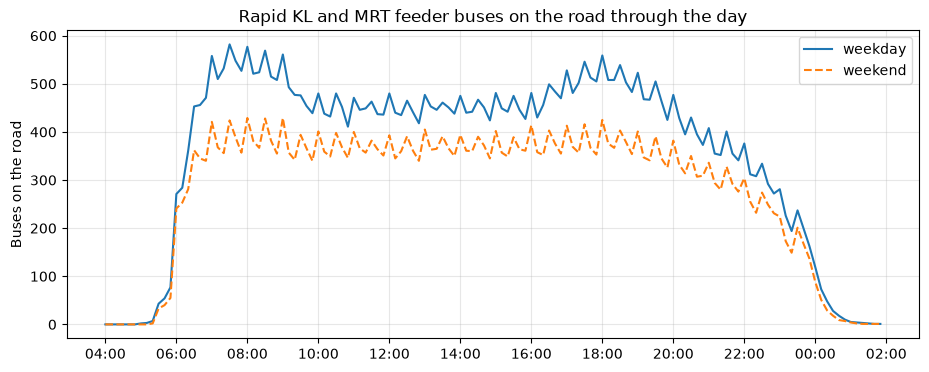

In [14]:
import matplotlib.pyplot as plt

clock = np.arange(4 * 3600, 26 * 3600, 600)
fig, ax = plt.subplots(figsize=(11, 4))
for day, style in [("weekday", "-"), ("weekend", "--")]:
    r = runs[runs["day"] == day]
    on_road = [((r["start"] <= t) & (r["start"] + r["duration"] >= t)).sum() for t in clock]
    ax.plot(clock / 3600, on_road, style, label=day)
    print(f"{day}: most buses on the road at once: {max(on_road):,} at "
          f"{int(clock[int(np.argmax(on_road))] // 3600):02d}:{int(clock[int(np.argmax(on_road))] % 3600 // 60):02d}")
ax.set_xticks(range(4, 27, 2)); ax.set_xticklabels([f"{h % 24:02d}:00" for h in range(4, 27, 2)])
ax.set_ylabel("Buses on the road"); ax.set_title("Rapid KL and MRT feeder buses on the road through the day")
ax.legend(); ax.grid(alpha=0.3)
plt.savefig(OUTPUT / "stage3_buses_preview.png", dpi=100, bbox_inches="tight")
plt.show()

___
**END**